# Modelo 1 — `delivery_risk_classifier`
### ¿Llegará a tiempo este pedido?

**Objetivo:** Clasificación binaria que predice si un pedido tiene riesgo de retraso.  
**Output:** Score de riesgo `[0.0 - 1.0]` que el agente logístico consume como tool.  
**Datos:** Brazilian E-Commerce (Olist) + features sintéticos mapeados a México.  
**Modelo:** XGBoost Classifier

---

## Arquitectura de uso en el agente

```
Usuario → Gemini (orquestador)
              ↓
    tool: predict_delivery_risk(features)
              ↓
    delivery_risk_classifier.pkl
    → { risk_score: 0.78, label: 'ALTO', reason: 'zona_saturada' }
              ↓
    Gemini interpreta y responde al usuario
```

In [4]:
# Ejecutar solo la primera vez
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn kaggle joblib shap --quiet


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [22]:
%pip install statsmodels --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Instalación de dependencias

## 1. Imports y configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve
)
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('✅ Imports OK')

✅ Imports OK


## 2. Carga de datos — Olist (Kaggle)

Dataset: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

Descarga manual: `kaggle datasets download -d olistbr/brazilian-ecommerce`  
O descarga directa desde Kaggle y coloca los CSV en `./data/olist/`

In [2]:
DATA_PATH = './data/'

orders         = pd.read_csv(f'{DATA_PATH}olist_orders_dataset.csv')
order_items    = pd.read_csv(f'{DATA_PATH}olist_order_items_dataset.csv')
customers      = pd.read_csv(f'{DATA_PATH}olist_customers_dataset.csv')
products       = pd.read_csv(f'{DATA_PATH}olist_products_dataset.csv')
reviews        = pd.read_csv(f'{DATA_PATH}olist_order_reviews_dataset.csv')
sellers        = pd.read_csv(f'{DATA_PATH}olist_sellers_dataset.csv')
geolocation    = pd.read_csv(f'{DATA_PATH}olist_geolocation_dataset.csv')

print(f'Orders:      {orders.shape}')
print(f'Items:       {order_items.shape}')
print(f'Customers:   {customers.shape}')
print(f'Products:    {products.shape}')
print(f'Reviews:     {reviews.shape}')

Orders:      (99441, 8)
Items:       (112650, 7)
Customers:   (99441, 5)
Products:    (32951, 9)
Reviews:     (99224, 7)


## 3. Exploración inicial (EDA)

In [3]:
print('=== ORDERS STATUS ===')
print(orders['order_status'].value_counts())
print(f'\nNulls en fechas de entrega:')
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 
             'order_estimated_delivery_date']
print(orders[date_cols].isnull().sum())

=== ORDERS STATUS ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Nulls en fechas de entrega:
order_purchase_timestamp            0
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [4]:
# Convertir fechas
for col in date_cols + ['order_approved_at', 'order_delivered_carrier_date']:
    orders[col] = pd.to_datetime(orders[col])

# Solo pedidos entregados (tienen fecha real de entrega)
df_delivered = orders[orders['order_status'] == 'delivered'].copy()
df_delivered = df_delivered.dropna(subset=['order_delivered_customer_date', 
                                            'order_estimated_delivery_date'])

print(f'Pedidos entregados con fechas completas: {len(df_delivered):,}')

Pedidos entregados con fechas completas: 96,470


Distribución del target:
is_delayed
0    89936
1     6534
Name: count, dtype: int64

% de retrasos: 6.8%


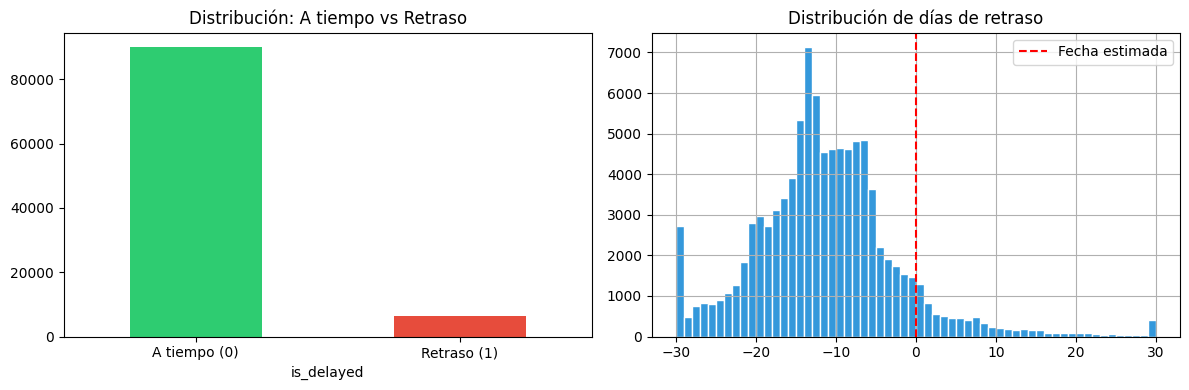

In [5]:
# ====================================================
# TARGET: ¿Llegó tarde?
# 1 = RETRASO (llegó después de la fecha estimada)
# 0 = A TIEMPO
# ====================================================
df_delivered['delay_days'] = (
    df_delivered['order_delivered_customer_date'] - 
    df_delivered['order_estimated_delivery_date']
).dt.days

df_delivered['is_delayed'] = (df_delivered['delay_days'] > 0).astype(int)

print('Distribución del target:')
print(df_delivered['is_delayed'].value_counts())
print(f'\n% de retrasos: {df_delivered["is_delayed"].mean():.1%}')

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_delivered['is_delayed'].value_counts().plot(
    kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'], rot=0
)
axes[0].set_title('Distribución: A tiempo vs Retraso')
axes[0].set_xticklabels(['A tiempo (0)', 'Retraso (1)'])

df_delivered['delay_days'].clip(-30, 30).hist(
    bins=60, ax=axes[1], color='#3498db', edgecolor='white'
)
axes[1].axvline(0, color='red', linestyle='--', label='Fecha estimada')
axes[1].set_title('Distribución de días de retraso')
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Feature Engineering

In [6]:
# ====================================================
# 4.1 Features temporales del pedido
# ====================================================
df_delivered['purchase_hour']       = df_delivered['order_purchase_timestamp'].dt.hour
df_delivered['purchase_dayofweek']  = df_delivered['order_purchase_timestamp'].dt.dayofweek
df_delivered['purchase_month']      = df_delivered['order_purchase_timestamp'].dt.month
df_delivered['purchase_day']        = df_delivered['order_purchase_timestamp'].dt.day

# Días estimados de entrega (lo que prometió el sistema)
df_delivered['estimated_days'] = (
    df_delivered['order_estimated_delivery_date'] - 
    df_delivered['order_purchase_timestamp']
).dt.days

# Días hasta que el carrier tomó el paquete
df_delivered['days_to_carrier'] = (
    df_delivered['order_delivered_carrier_date'] - 
    df_delivered['order_purchase_timestamp']
).dt.days

# Es fin de semana?
df_delivered['is_weekend'] = (df_delivered['purchase_dayofweek'] >= 5).astype(int)

print('Features temporales creadas ✅')

Features temporales creadas ✅


In [7]:
# ====================================================
# 4.2 Join con items (peso, precio, cantidad)
# ====================================================
items_agg = order_items.groupby('order_id').agg(
    num_items       = ('order_item_id', 'count'),
    total_price     = ('price', 'sum'),
    total_freight   = ('freight_value', 'sum'),
    num_sellers     = ('seller_id', 'nunique')
).reset_index()

products_agg = order_items.merge(products[['product_id', 'product_weight_g', 
                                            'product_length_cm']], 
                                  on='product_id', how='left')
products_agg = products_agg.groupby('order_id').agg(
    total_weight_g  = ('product_weight_g', 'sum'),
    max_length_cm   = ('product_length_cm', 'max')
).reset_index()

df = df_delivered.merge(items_agg, on='order_id', how='left')
df = df.merge(products_agg, on='order_id', how='left')

print(f'Shape después de join con items: {df.shape}')

Shape después de join con items: (96470, 23)


In [8]:
# ====================================================
# 4.3 Join con clientes (estado/región)
# ====================================================
df = df.merge(
    customers[['customer_id', 'customer_state', 'customer_city']], 
    on='customer_id', how='left'
)

# Tasa histórica de retraso por estado del cliente
state_delay_rate = df.groupby('customer_state')['is_delayed'].mean().to_dict()
df['state_delay_rate'] = df['customer_state'].map(state_delay_rate)

print('Features de cliente/región creadas ✅')
print('\nTop 5 estados con más retrasos:')
print(df.groupby('customer_state')['is_delayed']
        .agg(['mean','count'])
        .query('count > 100')
        .sort_values('mean', ascending=False)
        .head())

Features de cliente/región creadas ✅

Top 5 estados con más retrasos:
                    mean  count
customer_state                 
AL              0.214106    397
MA              0.174338    717
SE              0.152239    335
PI              0.138655    476
CE              0.137608   1279


In [9]:
# ====================================================
# 4.4 Features de reviews (historial del cliente)
# Proxy: si el cliente ha tenido malas experiencias antes
# ====================================================
reviews_clean = reviews[['order_id', 'review_score']].dropna()
df = df.merge(reviews_clean, on='order_id', how='left')

print('Reviews joined ✅')

Reviews joined ✅


In [10]:
# ====================================================
# 4.5 Features sintéticas — Adaptación a México
# Aquí es donde "mexicanizamos" el dataset
# ====================================================
n = len(df)

# Quincena mexicana (1-2 del mes o 15-17 son picos de demanda)
df['es_quincena'] = df['purchase_day'].apply(
    lambda d: 1 if d in [1, 2, 14, 15, 16, 17] else 0
)

# Zonas de México mapeadas a estados de Brasil (proxy)
#
ZONA_MAP = {
    'SP': 'CDMX',      'RJ': 'GDL',       'MG': 'MTY',
    'RS': 'PUE',       'PR': 'QRO',       'SC': 'MER',
    'BA': 'SLP',       'GO': 'HMO',       'ES': 'TIJ',
    'PE': 'VER'
}
df['zona_mx'] = df['customer_state'].map(ZONA_MAP).fillna('OTRO')

# Zonas conflictivas en México (alta tasa de fallo histórica)
ZONAS_CONFLICTIVAS = ['CDMX', 'MTY']  # alta densidad
df['es_zona_conflictiva'] = df['zona_mx'].isin(ZONAS_CONFLICTIVAS).astype(int)

# Tipo de cliente simulado (B2B vs consumidor final)
# En Alfaprom esto vendría de Odoo
np.random.seed(RANDOM_STATE)
df['tipo_cliente'] = np.random.choice(['B2B', 'B2C'], size=n, p=[0.3, 0.7])

# Intentos de entrega previos fallidos (simulado)
df['intentos_fallidos'] = np.random.choice([0, 1, 2, 3], size=n, p=[0.7, 0.2, 0.07, 0.03])

print('Features sintéticas México creadas ✅')
print(df['zona_mx'].value_counts())

Features sintéticas México creadas ✅
zona_mx
CDMX    40705
GDL     12420
MTY     11423
OTRO     9713
PUE      5381
QRO      4942
MER      3560
SLP      3273
TIJ      2004
HMO      1974
VER      1604
Name: count, dtype: int64


## 5. Preparación del dataset final

In [11]:
# ====================================================
# Features seleccionadas para el modelo
# Estas son las que el agente enviará en tiempo real
# ====================================================
FEATURES = [
    # Temporales
    'purchase_hour',
    'purchase_dayofweek',
    'purchase_month',
    'estimated_days',
    'days_to_carrier',
    'is_weekend',
    'es_quincena',
    
    # Pedido
    'num_items',
    'total_price',
    'total_freight',
    'total_weight_g',
    'num_sellers',
    'intentos_fallidos',
    
    # Zona/región
    'state_delay_rate',
    'es_zona_conflictiva',
    
    # Cliente
    'tipo_cliente',  # se encodea abajo
]

TARGET = 'is_delayed'

df_model = df[FEATURES + [TARGET]].dropna().copy()

# Encode tipo_cliente
le = LabelEncoder()
df_model['tipo_cliente'] = le.fit_transform(df_model['tipo_cliente'])

print(f'Dataset final: {df_model.shape}')
print(f'Target balance: {df_model[TARGET].value_counts().to_dict()}')

Dataset final: (96998, 17)
Target balance: {0: 90437, 1: 6561}


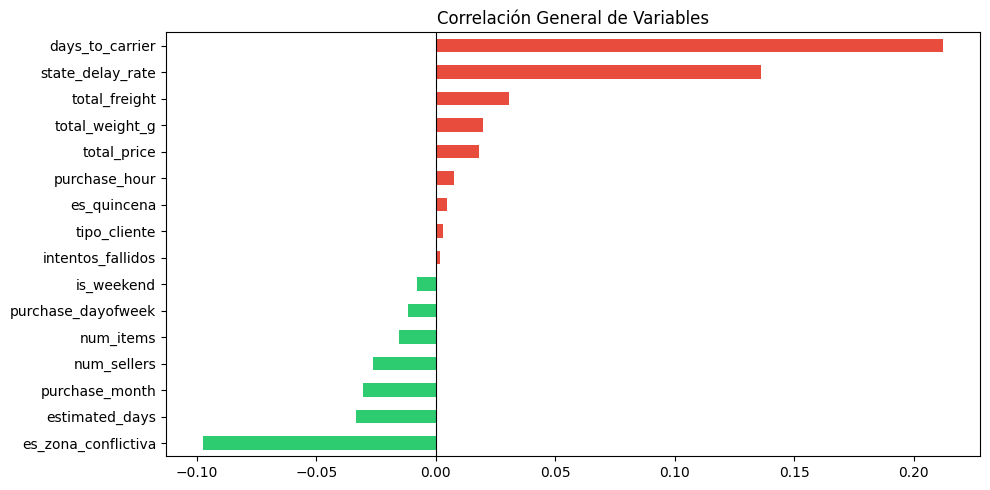

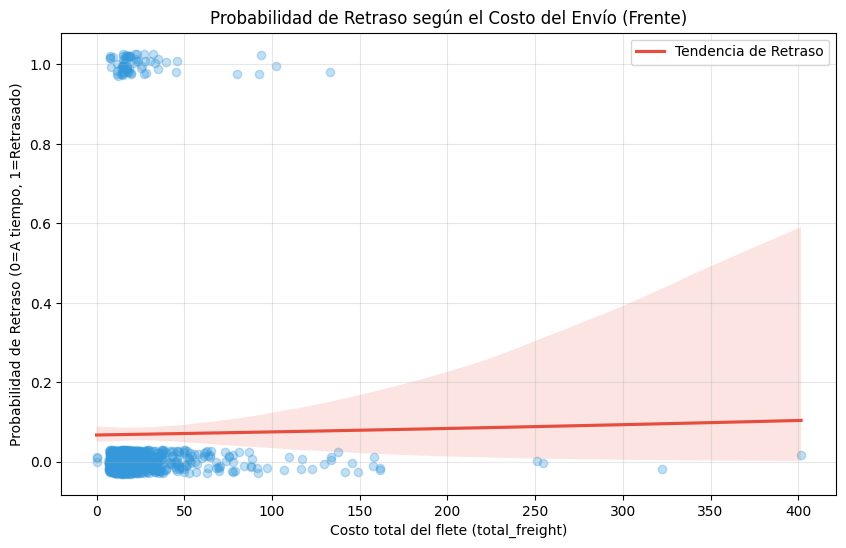

In [13]:
# ====================================================
# 1. Gráfica de Correlación General (Barras)
# ====================================================
plt.figure(figsize=(10, 5))
corr = df_model.corr()[TARGET].drop(TARGET).sort_values()
corr.plot(kind='barh', color=['#e74c3c' if v > 0 else '#2ecc71' for v in corr])
plt.title('Correlación General de Variables')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# ====================================================
# 2. Análisis detallado: ¿Afecta el costo del flete los retrasos?
# Usamos una muestra de 1,000 puntos para ver la tendencia claramente
# ====================================================
plt.figure(figsize=(10, 6))
# Tomamos una muestra para que los puntos se vean bien
df_sample = df_model.sample(n=min(1000, len(df_model)), random_state=42)

sns.regplot(data=df_sample, x='total_freight', y=TARGET, 
            logistic=True,             # Activa la curva de probabilidad
            y_jitter=0.03,             # Separa un poco los puntos del 0 y 1 para verlos mejor
            scatter_kws={'alpha':0.3, 'color':'#3498db'}, 
            line_kws={'color':'#e74c3c', 'label':'Tendencia de Retraso'})

plt.title('Probabilidad de Retraso según el Costo del Envío (Frente)')
plt.xlabel('Costo total del flete (total_freight)')
plt.ylabel('Probabilidad de Retraso (0=A tiempo, 1=Retrasado)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 6. Entrenamiento del modelo — XGBoost

In [14]:
X = df_model[FEATURES]
y = df_model[TARGET]

# Split estratificado (respeta balance de clases)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Balance train — 0: {(y_train==0).sum()} | 1: {(y_train==1).sum()}')

Train: (77598, 16) | Test: (19400, 16)
Balance train — 0: 72349 | 1: 5249


In [15]:
# ====================================================
# Manejo de desbalance de clases
# Si hay más pedidos a tiempo que retrasados,
# scale_pos_weight compensa esto
# ====================================================
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

model = XGBClassifier(
    n_estimators        = 300,
    max_depth           = 6,
    learning_rate       = 0.05,
    subsample           = 0.8,
    colsample_bytree    = 0.8,
    scale_pos_weight    = scale_pos_weight,
    use_label_encoder   = False,
    eval_metric         = 'logloss',
    random_state        = RANDOM_STATE,
    n_jobs              = -1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

print('\n✅ Modelo entrenado')

scale_pos_weight: 13.78
[0]	validation_0-logloss:0.68345
[50]	validation_0-logloss:0.49887
[100]	validation_0-logloss:0.46987
[150]	validation_0-logloss:0.45533
[200]	validation_0-logloss:0.44344
[250]	validation_0-logloss:0.43274
[299]	validation_0-logloss:0.42428

✅ Modelo entrenado


## 7. Evaluación

In [17]:
y_pred      = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['A tiempo', 'Retraso']))
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob):.4f}')

=== Classification Report ===
              precision    recall  f1-score   support

    A tiempo       0.97      0.81      0.89     18088
     Retraso       0.22      0.71      0.33      1312

    accuracy                           0.81     19400
   macro avg       0.60      0.76      0.61     19400
weighted avg       0.92      0.81      0.85     19400

ROC-AUC Score: 0.8377


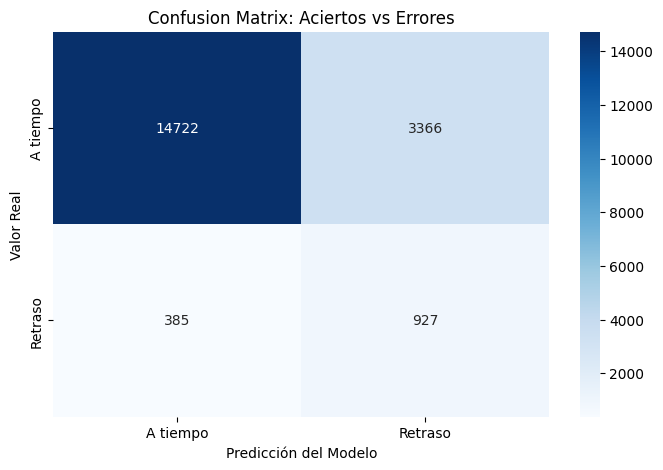

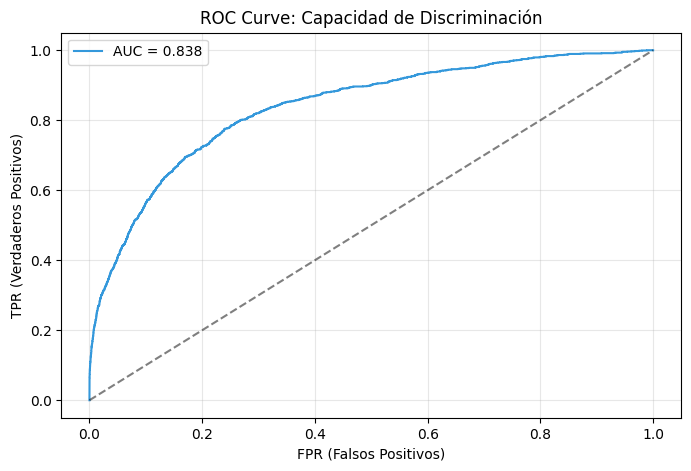

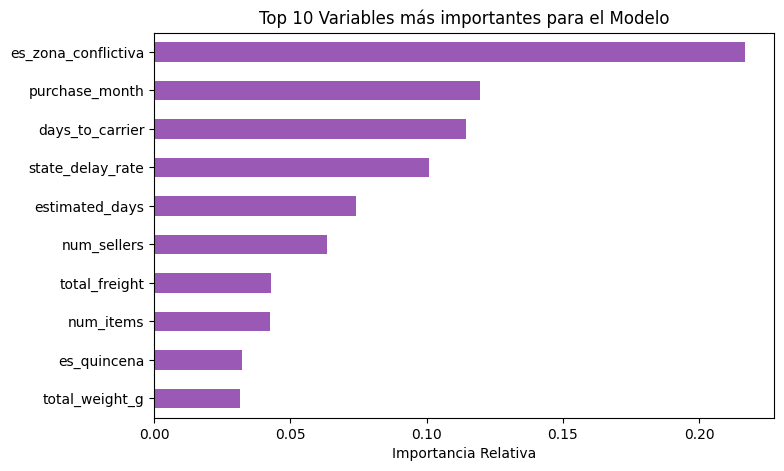

In [19]:
# 1. Matriz de Confusión (Confusion Matrix) — Para ver cuántos aciertos/errores reales hay
plt.figure(figsize=(8, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['A tiempo', 'Retraso'],
            yticklabels=['A tiempo', 'Retraso'])
plt.title('Confusion Matrix: Aciertos vs Errores')
plt.ylabel('Valor Real')
plt.xlabel('Predicción del Modelo')
plt.show()

# 2. Curva ROC (ROC Curve) — Para ver qué tan bueno es el modelo separando las clases
plt.figure(figsize=(8, 5))
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc = roc_auc_score(y_test, y_pred_prob)
plt.plot(fpr, tpr, color='#3498db', label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1], 'k--', alpha=0.5) # Línea base (si el modelo fuera al azar)
plt.title('ROC Curve: Capacidad de Discriminación')
plt.xlabel('FPR (Falsos Positivos)')
plt.ylabel('TPR (Verdaderos Positivos)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Importancia de Variables (Feature Importance) — Para ver qué datos "le importan" más al modelo
plt.figure(figsize=(8, 5))
feat_imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True)
feat_imp.tail(10).plot(kind='barh', color='#9b59b6')
plt.title('Top 10 Variables más importantes para el Modelo')
plt.xlabel('Importancia Relativa')
plt.show()


In [20]:
# ====================================================
# Cross-validation para validar que no hay overfitting
# ====================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f'CV ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')
print(f'Scores por fold: {cv_scores.round(4)}')

CV ROC-AUC: 0.8363 ± 0.0026
Scores por fold: [0.8328 0.8381 0.8368 0.8399 0.8338]


## 8. Interpretabilidad con SHAP

SHAP nos dice **por qué** el modelo predice lo que predice. Clave para explicarle al cliente y para debuggear el agente.

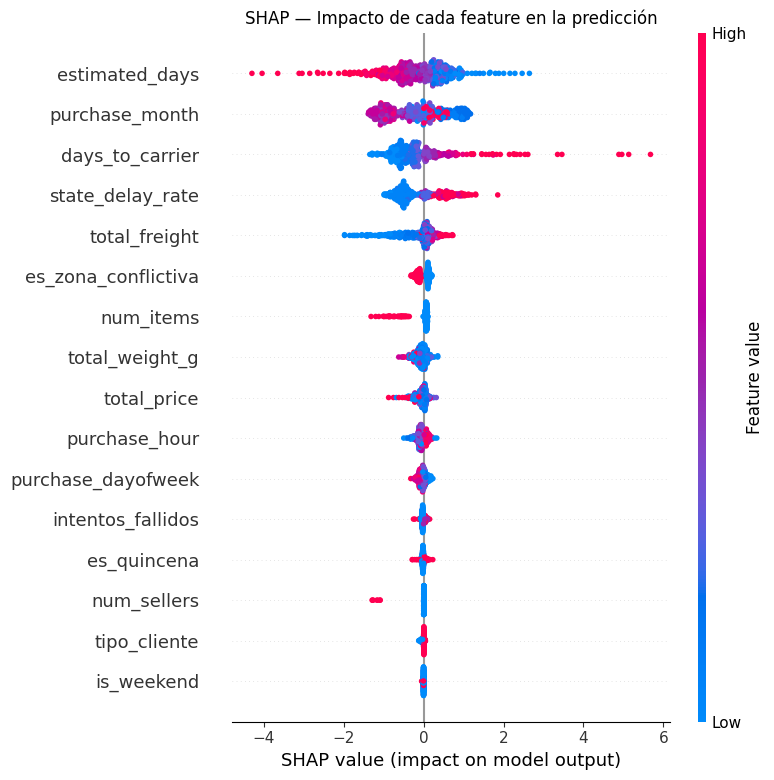

In [21]:
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test.sample(500, random_state=RANDOM_STATE))

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test.sample(500, random_state=RANDOM_STATE), 
                  feature_names=FEATURES, show=False)
plt.title('SHAP — Impacto de cada feature en la predicción')
plt.tight_layout()
plt.show()

## 9. Exportar modelo

In [22]:
MODEL_PATH = './models/delivery_risk_classifier.pkl'

import os
os.makedirs('./models', exist_ok=True)

# Guardamos el modelo y metadata necesaria para el agente
model_artifact = {
    'model'         : model,
    'features'      : FEATURES,
    'label_encoder' : le,
    'version'       : '1.0.0',
    'target'        : TARGET,
    'roc_auc'       : round(auc, 4),
    'thresholds'    : {
        'low'    : 0.3,   # < 30% → a tiempo
        'medium' : 0.6,   # 30-60% → riesgo medio
        'high'   : 0.6    # > 60% → riesgo alto
    }
}

joblib.dump(model_artifact, MODEL_PATH)
print(f'✅ Modelo exportado: {MODEL_PATH}')
print(f'   Tamaño: {os.path.getsize(MODEL_PATH) / 1024:.1f} KB')

✅ Modelo exportado: ./models/delivery_risk_classifier.pkl
   Tamaño: 1252.1 KB


## 10. Función de predicción para el agente

Esta es la función que el FastAPI endpoint va a exponer como tool del agente.

In [ ]:
def predict_delivery_risk(features: dict) -> dict:
    """
    Predice el riesgo de retraso de un pedido.
    
    Esta función es el contrato entre el modelo y el agente.
    El agente envía un dict con los features, recibe un dict con el resultado.
    
    Args:
        features: dict con los campos definidos en FEATURES
    
    Returns:
        dict con:
            - risk_score: float [0.0 - 1.0]
            - risk_label: str [BAJO | MEDIO | ALTO]
            - top_reasons: list de features más influyentes
    """
    artifact = joblib.load(MODEL_PATH)
    clf      = artifact['model']
    feats    = artifact['features']
    
    # Encode tipo_cliente
    features['tipo_cliente'] = artifact['label_encoder'].transform(
        [features['tipo_cliente']]
    )[0]
    
    X_input     = pd.DataFrame([features])[feats]
    risk_score  = clf.predict_proba(X_input)[0][1]
    
    thresholds = artifact['thresholds']
    if risk_score < thresholds['low']:
        label = 'BAJO'
    elif risk_score < thresholds['high']:
        label = 'MEDIO'
    else:
        label = 'ALTO'
    
    return {
        'risk_score' : round(float(risk_score), 4),
        'risk_label' : label,
    }


# ====================================================
# Test de la función con un pedido de ejemplo
# ====================================================
ejemplo_pedido = {
    'purchase_hour'      : 18,       # tarde
    'purchase_dayofweek' : 4,        # viernes
    'purchase_month'     : 12,       # diciembre (época alta)
    'estimated_days'     : 7,
    'days_to_carrier'    : 3,        # tardó 3 días en salir al carrier
    'is_weekend'         : 0,
    'es_quincena'        : 0,
    'num_items'          : 2,
    'total_price'        : 450.0,
    'total_freight'      : 35.0,
    'total_weight_g'     : 1200,
    'num_sellers'        : 1,
    'intentos_fallidos'  : 1,        # ya falló un intento
    'state_delay_rate'   : 0.35,     # zona con 35% de retrasos históricos
    'es_zona_conflictiva': 1,        # zona conflictiva
    'tipo_cliente'       : 'B2C',
}

resultado = predict_delivery_risk(ejemplo_pedido)
print('=== Predicción de ejemplo ===')
print(f'Risk Score: {resultado["risk_score"]}')
print(f'Risk Label: {resultado["risk_label"]}')
print(f'\nContexto para Gemini:')
print(f'El pedido tiene riesgo {resultado["risk_label"]} de retraso ({resultado["risk_score"]*100:.1f}%)')

---

## Siguientes pasos

1. **FastAPI endpoint** → `POST /predict/delivery-risk` que expone `predict_delivery_risk()`
2. **MCP Tool** en el agente que llama ese endpoint
3. **Modelo 2** → `proactive_attention_classifier` (cliente que necesita contacto antes de quejarse)
4. **Con datos reales de Alfaprom** → reentrenar con features exactos de Odoo

```
Agente logístico con este modelo:

Sin modelo: "Tu pedido está en tránsito"
Con modelo: "Tu pedido tiene riesgo ALTO de retraso (78%).
             Basado en el tráfico en tu zona y que ya
             hubo un intento fallido, recomiendo
             reagendar para mañana AM. ¿Confirmas?"
```